# Customer Segmentation with K-Means and Hierarchical Clustering

Customer segmentation groups customers with similar demographic, purchasing, and campaign-related characteristics. This notebook explores the **Customer Personality Analysis** dataset using K-Means and Agglomerative Clustering, with Silhouette Score for internal evaluation.

**Methods:** StandardScaler, K-Means, Agglomerative Clustering, Principal Component Analysis (PCA), Elbow Method, and Silhouette Score.

## 1. Dataset Upload

Upload `marketing_campaign.csv` to the Colab session. The dataset is expected to be a tab-separated file.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving marketing_campaign.csv to marketing_campaign.csv


## 2. Libraries

Pandas and NumPy handle the data, scikit-learn provides clustering and preprocessing methods, and Matplotlib is used for visualizations.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

## 3. Dataset Inspection

Load the marketing campaign data and inspect the first rows to verify its columns and format.

In [ ]:
df = pd.read_csv('marketing_campaign.csv', sep='\t')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## 4. Data Preprocessing

Missing records are removed, the customer date is parsed, and customer age is calculated from `Year_Birth` using **2026** as the reference year. Categorical columns are one-hot encoded, while the two constant campaign-cost columns and the original date and birth-year fields are removed.

The remaining feature set includes `ID`; because it is an identifier rather than a customer characteristic, its inclusion can influence distance-based clustering. This is a modeling limitation of the current implementation.

In [ ]:
df.columns = df.columns.str.strip()

df = df.dropna()

df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], dayfirst=True)

df['Age'] = 2026 - df['Year_Birth']

df = df.drop(['Year_Birth', 'Dt_Customer'], axis=1)

df = pd.get_dummies(df)

df = df.drop(['Z_CostContact', 'Z_Revenue'], axis=1)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2216 entries, 0 to 2239
Data columns (total 37 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       2216 non-null   int64  
 1   Income                   2216 non-null   float64
 2   Kidhome                  2216 non-null   int64  
 3   Teenhome                 2216 non-null   int64  
 4   Recency                  2216 non-null   int64  
 5   MntWines                 2216 non-null   int64  
 6   MntFruits                2216 non-null   int64  
 7   MntMeatProducts          2216 non-null   int64  
 8   MntFishProducts          2216 non-null   int64  
 9   MntSweetProducts         2216 non-null   int64  
 10  MntGoldProds             2216 non-null   int64  
 11  NumDealsPurchases        2216 non-null   int64  
 12  NumWebPurchases          2216 non-null   int64  
 13  NumCatalogPurchases      2216 non-null   int64  
 14  NumStorePurchases        2216

## 5. Feature Standardization

`StandardScaler` centers each feature and scales it by its standard deviation. This reduces the effect of different numeric ranges on distance-based clustering.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

## 6. Selecting the Number of Clusters

K-Means is evaluated for **k = 2–10** using the Elbow Method (inertia) and Silhouette Score. Inertia measures within-cluster variation, while Silhouette Score summarizes cluster separation and cohesion.

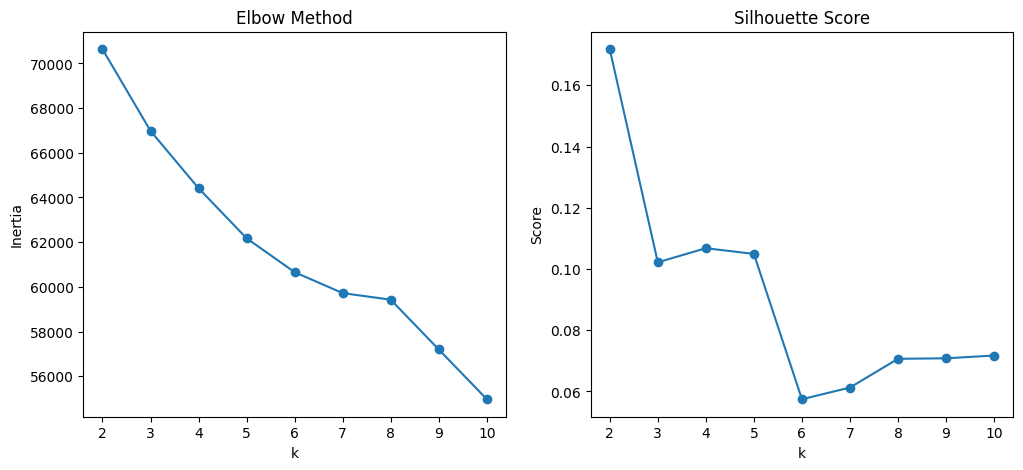

In [ ]:
inertia = []
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12,5))

ax[0].plot(range(2,11), inertia, marker='o')
ax[0].set_title('Elbow Method')
ax[0].set_xlabel('k')
ax[0].set_ylabel('Inertia')

ax[1].plot(range(2,11), silhouette_scores, marker='o')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('k')
ax[1].set_ylabel('Score')

plt.show()

## 7. K-Means Clustering

The notebook selects **k = 4** for the subsequent K-Means model. This is a manual choice based on the plotted diagnostics, not a formally established optimum.

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

score_kmeans = silhouette_score(X_scaled, labels_kmeans)
print("Silhouette Score K-Means:", score_kmeans)

Silhouette Score K-Means: 0.1068005102912317


## 8. Cluster Visualization with PCA

PCA projects the standardized features into two dimensions for plotting. The scatter plot shows the K-Means cluster assignments in the reduced feature space; PCA is used here for visualization, not for training the clustering model.

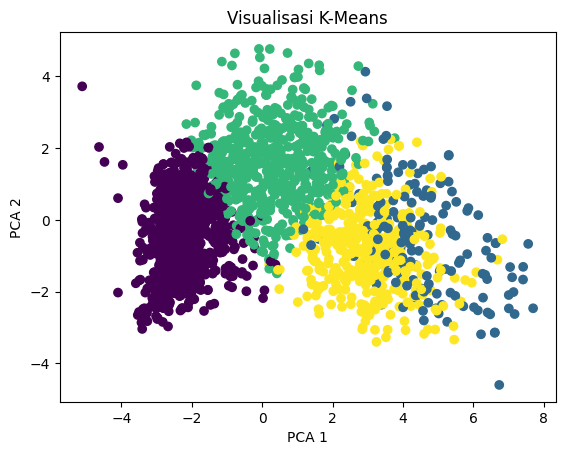

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_kmeans)
plt.title("Visualisasi K-Means")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

## 9. Agglomerative Clustering

Hierarchical clustering is evaluated with **single**, **complete**, **average**, and **ward** linkage, using four clusters for each method. Results are scored on the standardized features and displayed on the same two-dimensional PCA projection.

Silhouette Score (single): 0.7202240191958217


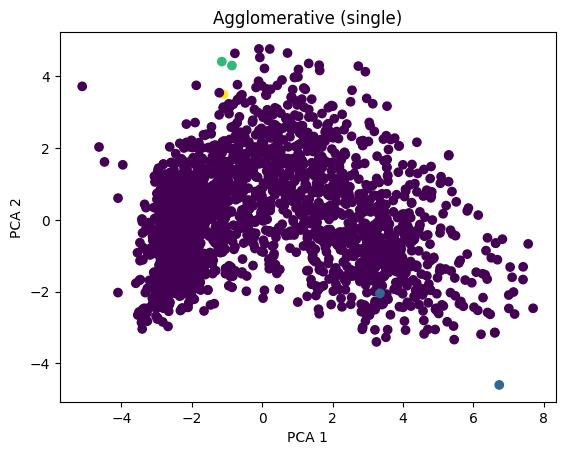

Silhouette Score (complete): 0.7202240191958217


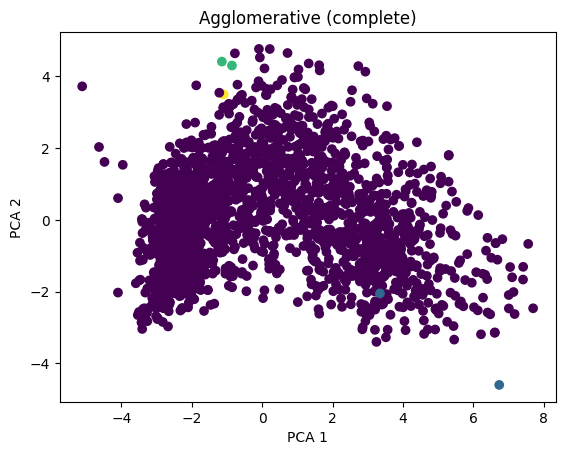

Silhouette Score (average): 0.7202240191958217


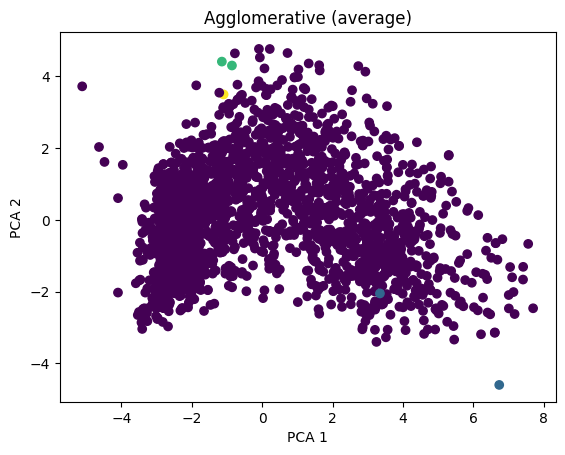

Silhouette Score (ward): 0.10889135409965793


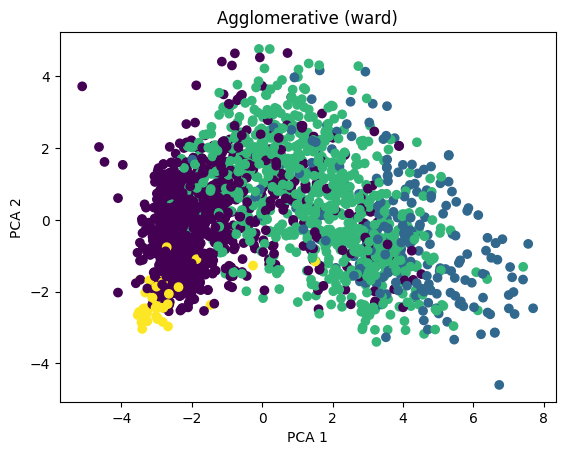

In [ ]:
linkages = ['single', 'complete', 'average', 'ward']
scores = {}

for link in linkages:
    agg = AgglomerativeClustering(n_clusters=4, linkage=link)
    labels = agg.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    scores[link] = score

    print(f"Silhouette Score ({link}):", score)

    plt.figure()
    plt.scatter(X_pca[:,0], X_pca[:,1], c=labels)
    plt.title(f"Agglomerative ({link})")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.show()


## 10. Results and Discussion

| Method | Clusters | Silhouette Score |
|---|---:|---:|
| K-Means | 4 | 0.1068 |
| Agglomerative — Single | 4 | 0.7202 |
| Agglomerative — Complete | 4 | 0.7202 |
| Agglomerative — Average | 4 | 0.7202 |
| Agglomerative — Ward | 4 | 0.1089 |

Single, complete, and average linkage have the highest reported Silhouette Scores. However, these values alone do not confirm useful customer segments: cluster sizes and the influence of outliers should also be inspected. The current notebook does not produce customer profiles or a separate validation set.

## 11. Conclusion

The notebook demonstrates preprocessing, feature scaling, cluster selection, and comparison of partition-based and hierarchical clustering. The results provide an initial segmentation analysis; interpreting the clusters would require reviewing their sizes and customer characteristics.